In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'  

os.makedirs("Results", exist_ok=True)
from scipy.interpolate import CubicSpline as CS
import torch
import numpy as np
import torch.nn as nn
from torch.autograd import grad
import matplotlib.pyplot as plt
import torch.nn.functional as F
from timeit import default_timer
import scipy.signal
import scipy
import pickle
from scipy.interpolate import PchipInterpolator as PI

device = 'cuda' if torch.cuda.is_available() else 'cpu'


torch.set_default_dtype(torch.float32)

In [2]:
def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    if device == 'cuda':
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [89]:
a=7
batch_size_pde=2001
x_intp=np.linspace(-a,a,batch_size_pde)

def bbr(q,om):
    value=-np.exp(om*q/2)*(np.cos(np.sqrt(3)/2*om*q)+1/np.sqrt(3)*np.sin(np.sqrt(3)/2*om*q))
    return value

def csrS(q):
    return -4*np.pi*q**(-1/3)*3**(-1/3)

def csr(q):
    return 4*np.pi*q**(-4/3)*3**(-4/3)

In [90]:
# distributions and currents
files = [
    (r"D:\dis_pp\csr_7_1000_0.1",  0.1),
    (r"D:\dis_pp\csr_7_1000_0.2", 0.2),
    (r"D:\dis_pp\csr_7_1000_0.3",  0.3),
    (r"D:\dis_pp\csr_7_1000_0.4",  0.4),
]

data0 = pickle.load(open(files[0][0], 'rb'))
xtt = np.linspace(-7, 7, np.shape(data0)[0])

# the function of disributions λ(q)
func_CS_list = [
    CS(xtt, pickle.load(open(path, 'rb')).T[0])
    for path, _ in files
]

# currents
I_norm = np.array([n for _, n in files])

# input vector
u_given   = np.hstack([np.atleast_2d(f(x_intp)).T           for f in func_CS_list])
u_x_given = np.hstack([np.atleast_2d(f.derivative()(x_intp)).T for f in func_CS_list])

u_given   = torch.from_numpy(u_given).float().to(device)
u_x_given = torch.from_numpy(u_x_given).float().to(device)

In [91]:
# ## **2. 定义PINNs模型 - 使用硬约束**
class PINN(nn.Module):
    def __init__(self, input_dim=1, output_dim=1, hidden_dim=50, num_hidden=3):
        """
        input_dim: 1 for default
        output_dim: 1 for default
        hidden_dim: number of neurons
        num_hidden: number of hidden layers         
        """
        super(PINN, self).__init__()


        self.main_layers = nn.ModuleList([nn.Linear(input_dim, hidden_dim*2)])
        for _ in range(num_hidden - 1):
            self.main_layers.append(nn.Linear(hidden_dim, hidden_dim*2))
        self.main_layers.append(nn.Linear(hidden_dim, output_dim))
        
        self.local_layers = nn.ModuleList([nn.Linear(input_dim, hidden_dim*2)])
        for _ in range(num_hidden -1):
            self.local_layers.append(nn.Linear(hidden_dim, hidden_dim*2))
        self.local_layers.append(nn.Linear(hidden_dim, output_dim))
        

        self.eps = 1e-4
        self.alpha = nn.Parameter(torch.tensor([1e-4]))
        self.transition_rates = nn.Parameter(torch.tensor([1.0]))
        self.transition_point = nn.Parameter(torch.tensor([1.0]))
    def singular_factor(self, x):
        return (torch.sqrt(x**2 + self.eps**2)) ** (-torch.abs(self.alpha))
       
    def forward(self, x):
        #zero_value=torch.sigmoid((-self.transition_point) * self.transition_rates)
        #transition = (torch.sigmoid((torch.abs(x) -self.transition_point) * self.transition_rates)-zero_value)/(1-zero_value)
        transition = torch.sigmoid((torch.abs(x) -self.transition_point) * self.transition_rates)
        x_in = x / a
        mask = (x > 0).to(x.dtype)
       
        
        out = x_in
        for layer in self.main_layers[:-1]:
            h = layer(out)
            gate, value = h.chunk(2, dim=1)
            out = F.gelu(gate) * value#torch.tanh(gate) * value#tanh
        g_main = self.main_layers[-1](out)
        
        out = x_in
        for layer in self.local_layers[:-1]:
            h = layer(out)
            gate, value = h.chunk(2, dim=1)
            out = F.gelu(gate) * value#torch.tanh(gate) * value#tanh
        g_local = self.local_layers[-1](out)
        
        Phi = self.singular_factor(x)
        W = mask * (Phi * (1-transition)* g_local + g_main*(transition))
        
        return W
    def calculate_derivatives(self, x,scd='False'):

        x = x.requires_grad_()
        u_pred = self.forward(x)
        
        if scd=='True':
            u_xx = grad(u_x, x, grad_outputs=torch.ones_like(u_pred),  create_graph=True,retain_graph=True)[0]
            return u_pred, u_xx  
        else:
            u_x = grad(u_pred, x, grad_outputs=torch.ones_like(u_pred),  create_graph=True,retain_graph=True)[0]
            return u_pred, u_x
            
    def losses(self, x):
        x_combined = x['pde']
        
        wake_pred, wake_pred_x = self.calculate_derivatives(x_combined,scd='False')
        
        total_loss=0
        dx=2*a/(batch_size_pde-1)
       
        for i in range(0,4):
            
            u_for_conv = u_x_given[:,i].reshape(-1,1).T.unsqueeze(0)  # [1, 1, N]
            wake_kernel=wake_pred.flip(0).view(1, 1, -1)
            
            convolve_result = torch.nn.functional.conv1d(
                u_for_conv,wake_kernel,
                padding='same' 
            )
            

            convolve_tensor = convolve_result.squeeze().unsqueeze(1)  # [N, 1]
            
                     
            residual = u_x_given[:,i].reshape(-1,1) + (x_combined + I_norm[i] * convolve_tensor*dx) * u_given[:,i].reshape(-1,1)
            
           
            loss_pde = torch.mean((residual)**2)
            total_loss = loss_pde+total_loss
       
        
        
    
        
       # total_loss=total_loss
        
        if not hasattr(self, 'history'):
            self.history = {
                'loss_pde': []
            }


        self.history['loss_pde'].append(total_loss.item())
        
        return total_loss
    


def get_data(batch_size_pde):
    """
    batch_size_pde: number of PDE points
    """

    
    x = np.linspace(-a, a, batch_size_pde)

    x_pde = x
    x_pde_flat = x_pde.flatten()[:, None] 
    
    

    x_train = {'pde': x_pde_flat}
    

    for key in x_train.keys():
        x_train[key] = torch.from_numpy(x_train[key]).float().to(device)
    
    x_test = x.flatten()[:, None]
    
    
    x_test = torch.from_numpy(x_test).float().to(device)
    
    return x_test, x_train


In [132]:
def train_pinn_adam(pinn, x_train, epochs=5000, lr=1e-3):
    """
    pinn: PINN instance
    x_train: space coordinate
    epochs: 
    lr: learning rates
    """
    optimizer = torch.optim.Adam(pinn.parameters(), lr=lr)
    print("start Adam trainning...")
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss_pde = pinn.losses(x_train)
        loss_pde.backward(retain_graph=True)
        optimizer.step()
        if (epoch+1) % 1000 == 0:
            print(f"epoch {epoch+1}: PDE loss = {loss_pde.item():.6e}")
    print("Adam training done")

def train_pinn_lbfgs(pinn, x_train, max_iter=500, lr=0.1, tolerance_grad=1e-10, tolerance_change=1e-10):
    """
    pinn: PINN instance
    x_train: space coordinate
    lr: learning rates
    """
    
    optimizer = torch.optim.LBFGS(
        pinn.parameters(),
        lr=lr,
        max_iter=max_iter,
        tolerance_grad=tolerance_grad,
        tolerance_change=tolerance_change,
        line_search_fn="strong_wolfe",
        history_size=100
    )
    
    def closure():
        optimizer.zero_grad()
        loss_pde = pinn.losses(x_train)
        loss_pde.backward(retain_graph=True)
        return loss_pde
    
    print("start L-BFGS trainning...")
    optimizer.step(closure)
    print("L-BFGS training done")


def plot_loss_history(pinn):
    """
    pinn: PINN instance
    """
    # 检查是否记录了损失历史
    if not hasattr(pinn, 'history'):
        print("No loss history available.")
        return

    epochs = range(len(pinn.history['loss_pde']))

    plt.figure(figsize=(10, 6))
    plt.semilogy(epochs, pinn.history['loss_pde'], label='PDE Residual Loss')
    plt.title('Loss During Training')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (Log Scale)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [133]:
set_seed(666)
x_test,x_train= get_data(batch_size_pde)

model = PINN(
    input_dim=1, 
    output_dim=1, 
    hidden_dim=50, 
    num_hidden=4
).to(device)

t1 = default_timer()
train_pinn_adam(model, x_train, epochs=20000, lr=1e-4)
t2 = default_timer()
print(f"time cost：{t2 - t1} s")

plot_loss_history(model)

start Adam trainning...


KeyboardInterrupt: 

In [126]:
model.alpha

Parameter containing:
tensor([-0.3288], device='cuda:0', requires_grad=True)

C:\Users\Liyan Qin\AppData\Local\Temp\ipykernel_66404\3838280843.py:10: RuntimeWarning: divide by zero encountered in power
  return -4*np.pi*q**(-1/3)*3**(-1/3)
C:\Users\Liyan Qin\AppData\Local\Temp\ipykernel_66404\3838280843.py:10: RuntimeWarning: invalid value encountered in power
  return -4*np.pi*q**(-1/3)*3**(-1/3)


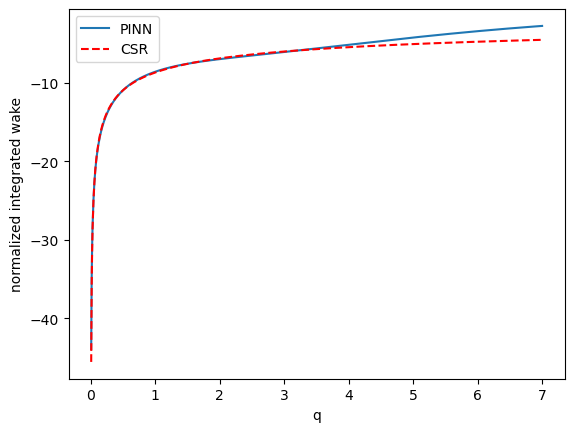

In [128]:
# ## **6. 结果评估与可视化**
x_plot=np.linspace(-7,7,2001).reshape(2001,1)
x_plot=torch.from_numpy(x_plot).float().to(device)
x0 = x_plot.cpu().detach().numpy()
u_pred,u_x=model.calculate_derivatives(x_plot)

u_plot = u_pred.cpu().detach().numpy()
plt.plot(x0[1001:],u_plot[1001:],label='PINN')
yy=csrS(x0)
yy[x0<=0]=0
plt.plot(x0[1001:],yy[1001:],linestyle='dashed',label='CSR',c='r')
#plt.xlim(-0.1,2)
#plt.ylim(-80,1)

plt.xlabel('q')
plt.ylabel('normalized integrated wake')
plt.legend()

C:\Users\Liyan Qin\AppData\Local\Temp\ipykernel_66404\3838280843.py:13: RuntimeWarning: divide by zero encountered in power
  return 4*np.pi*q**(-4/3)*3**(-4/3)
C:\Users\Liyan Qin\AppData\Local\Temp\ipykernel_66404\3838280843.py:13: RuntimeWarning: invalid value encountered in power
  return 4*np.pi*q**(-4/3)*3**(-4/3)


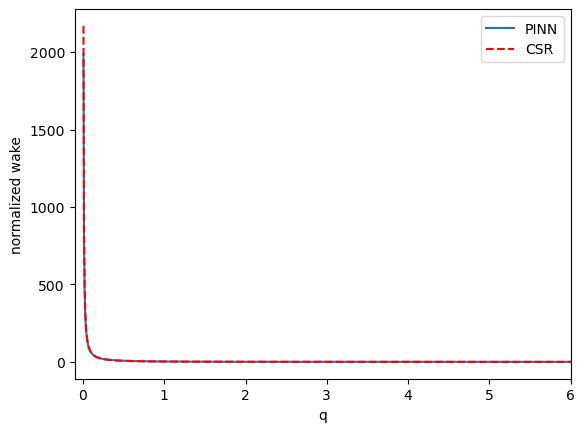

In [131]:
u_pred,u_x=model.calculate_derivatives(x_plot)

u_plot = u_x.cpu().detach().numpy()
plt.plot(x0[1001:],u_plot[1001:],label='PINN')
yy=csr(x0)
yy[x0<=0]=0
plt.plot(x0[1001:],yy[1001:],linestyle='dashed',label='CSR',c='r')
plt.xlim(-0.1,6)
plt.xlabel('q')
plt.ylabel('normalized wake')
plt.legend()

In [130]:
np.sum(np.abs((yy[1001:1430]-u_plot[1001:1430])))/np.sum(np.abs(yy[1001:1430]))

np.float32(0.06512763)

In [79]:
pickle.dump(np.hstack((x0,outS)).T, open(r'D:\haissinski_solver_data\wake_csrS', 'wb'))